# Compare mushroom results

Local trials requested by Tomislav. New mushroom review assigned to Muneeb; review pending. AI assistance: [record](../docs/AI_USE.md).

Read the frozen development results. Do not change settings after seeing them.

## Read the frozen counts

 Recall is poison caught divided by all poison. Specificity is edible unflagged divided by all edible.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
while not (ROOT / 'src/review_models.py').exists():
    if ROOT == ROOT.parent:
        raise RuntimeError('Open the notebook inside the review project.')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
results = pd.read_csv(ROOT / 'reports/research/mushroom_operating_comparison.csv')
selected = results[results.candidate.isin(['v3_extra_trees_0094', 'reference_random_forest'])]
display(selected[['candidate','policy','threshold','tp','fn','fp','tn','poison_recall','accuracy']])

,candidate,policy,threshold,tp,fn,fp,tn,poison_recall,accuracy
0,v3_extra_trees_0094,calibration_selected,0.205155,271,32,266,231,0.894389,0.62750
1,v3_extra_trees_0094,calibration_selected,0.146720,280,23,348,149,0.924092,0.53625
2,v3_extra_trees_0094,calibration_selected,0.083778,293,10,439,58,0.966997,0.43875
3,v3_extra_trees_0094,calibration_selected,0.060087,294,9,461,36,0.970297,0.41250
4,v3_extra_trees_0094,calibration_selected,0.039802,300,3,474,23,0.990099,0.40375
5,v3_extra_trees_0094,default_0.5,0.500000,181,122,42,455,0.597360,0.79500
18,reference_random_forest,calibration_selected,0.263987,263,40,263,234,0.867987,0.62125
19,reference_random_forest,calibration_selected,0.221440,277,26,346,151,0.914191,0.53500
20,reference_random_forest,calibration_selected,0.186306,288,15,385,112,0.950495,0.50000
21,reference_random_forest,calibration_selected,0.141070,295,8,456,41,0.973597,0.42000


## Decision

Extra Trees catches 300/303 poison labels but flags 474/497 edible labels. The cautious starter forest catches the same 300. Most recall gain comes from lowering the threshold. We did not find a useful zero-miss classifier.

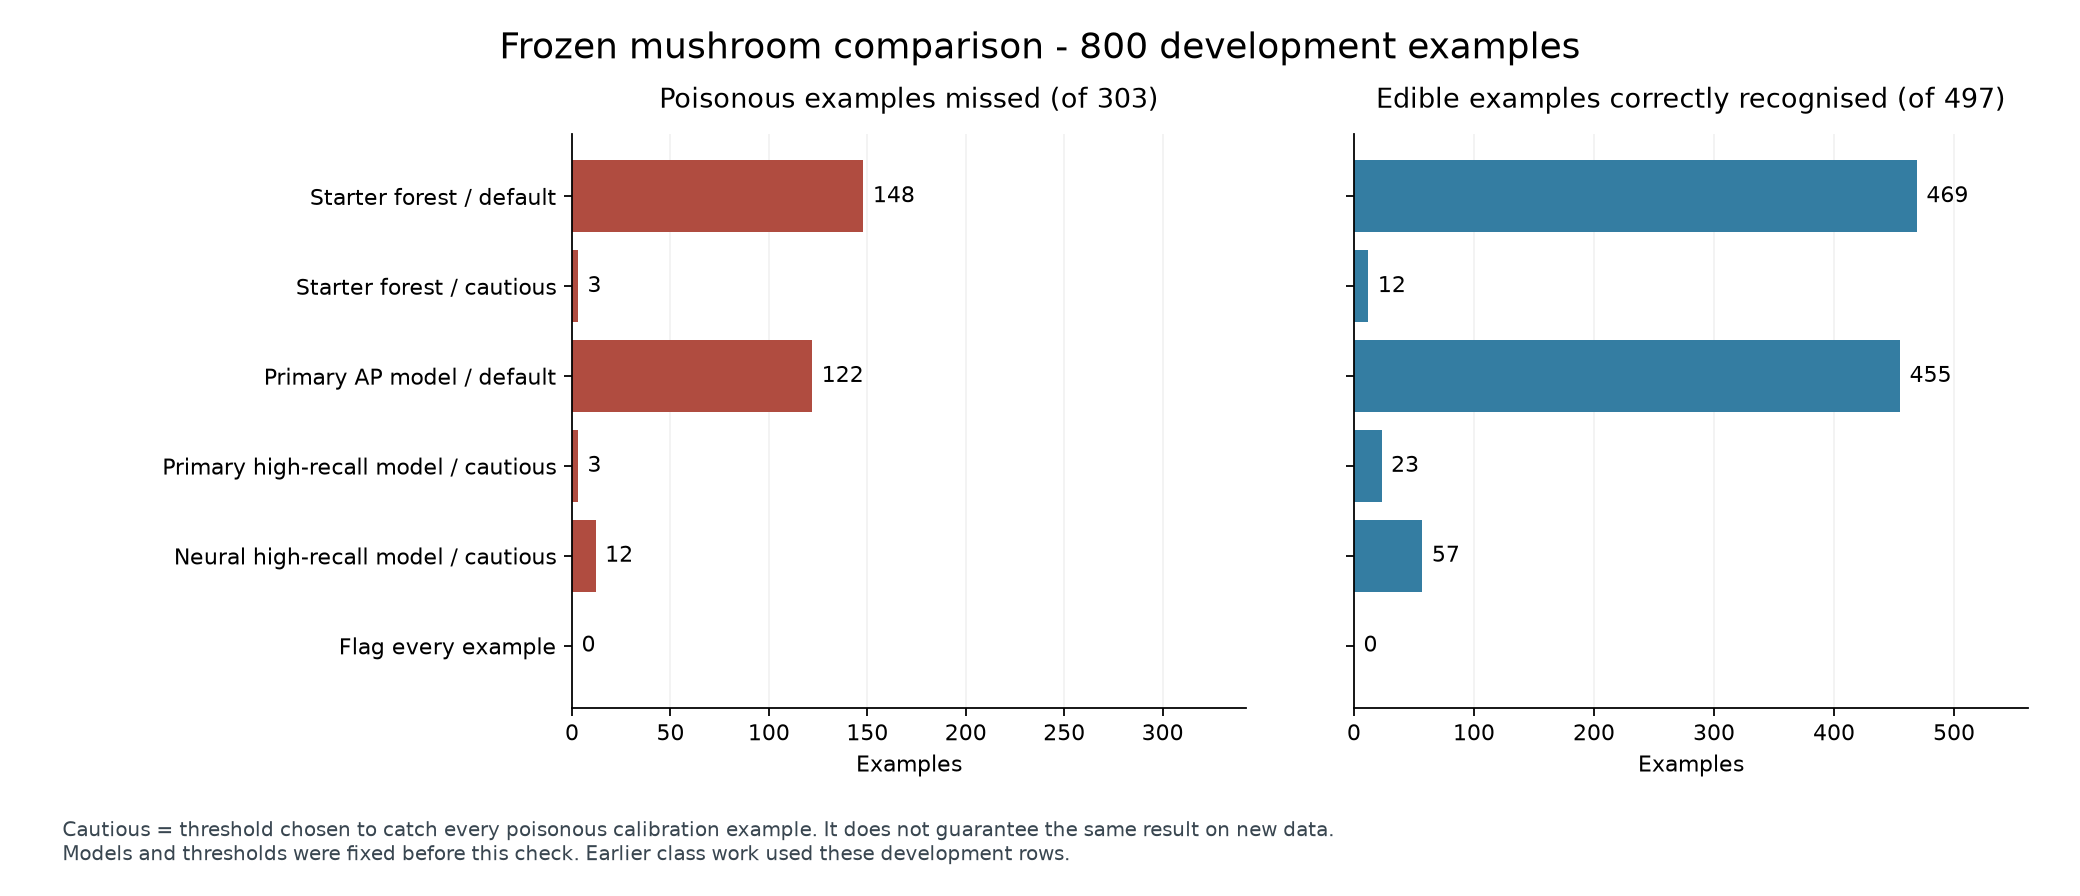

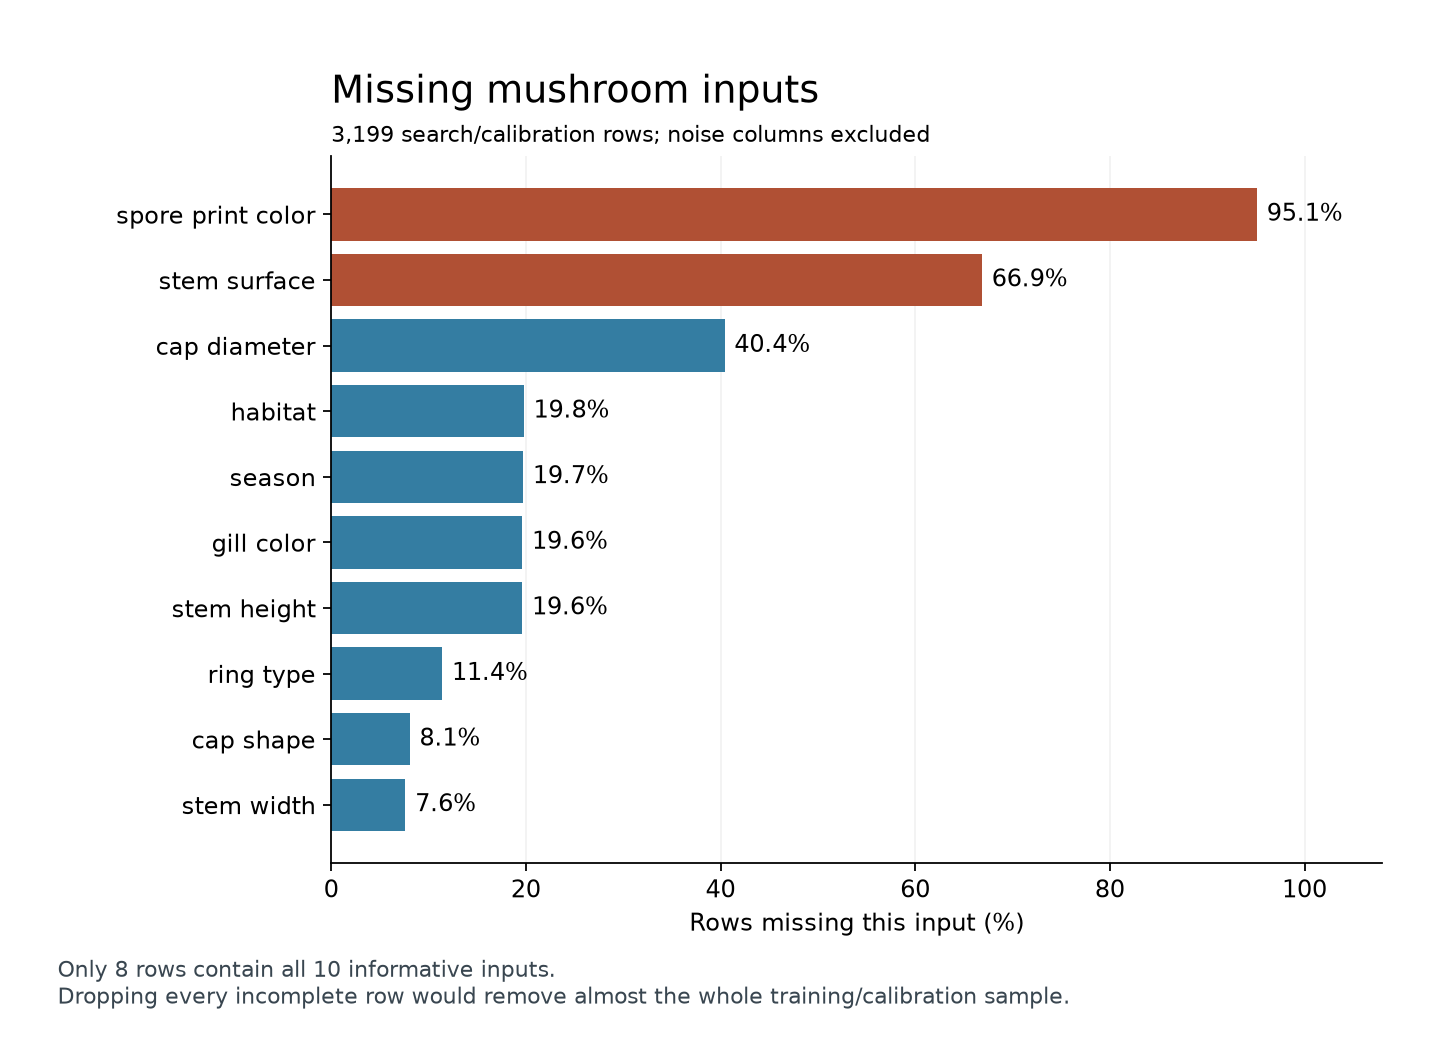

In [2]:
display(Image(filename=str(ROOT / 'reports/research/mushroom_frozen_tradeoff.png')))
display(Image(filename=str(ROOT / 'reports/research/mushroom_missing_inputs.png')))

## Why this preparation

Only eight search/calibration rows have all ten useful inputs. We keep incomplete rows. Iterative numeric filling, a missing-category token and guarded ratios belong inside each training fold. Noise removal helped; the imputer warning remains recorded.

## Try a feature-only input

 This is an already used training-side example, not an accuracy check. The saved model and thresholds are unchanged.

In [3]:
from src.review_models import mushroom_example, predict_mushroom
example = mushroom_example()
display(example)
display(predict_mushroom(example))
example['policy'] = 'default'
display(predict_mushroom(example))

{'policy': 'cautious',
 'features': {'cap-diameter': 5.78,
  'stem-height': 7.67,
  'stem-width': 8.21,
  'spore-print-color': None,
  'gill-color': 'r',
  'habitat': 'd',
  'season': 'u',
  'ring-type': 'f',
  'cap-shape': 'c',
  'stem-surface': None}}

{'model': 'Extra Trees',
 'research_score': 0.9692579365079363,
 'threshold': 0.0398015873015873,
 'flag_as_potentially_poisonous': True,
 'decision': 'Flagged as potentially poisonous',
 'note': 'Coursework prediction. This does not establish whether a mushroom is safe to eat.'}

{'model': 'Extra Trees',
 'research_score': 0.9692579365079363,
 'threshold': 0.5,
 'flag_as_potentially_poisonous': True,
 'decision': 'Flagged as potentially poisonous',
 'note': 'Coursework prediction. This does not establish whether a mushroom is safe to eat.'}

## Next

Run notebook 10 on AWS. Recalibrate any new fit. Freeze the release before the untouched final test.